In [1]:
from matplotlib import pyplot as plt
import numpy as np
import torch


In [2]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


**Download of CIFAR10**

In [3]:
from torchvision import datasets
data_path = '../data-unversioned/p1ch7/'
cifar10 = datasets.CIFAR10(data_path, train=True, download=True) # <1>
cifar10_val = datasets.CIFAR10(data_path, train=False, download=True) # <2>

100%|██████████| 170M/170M [20:59<00:00, 135kB/s]


**Classifications**

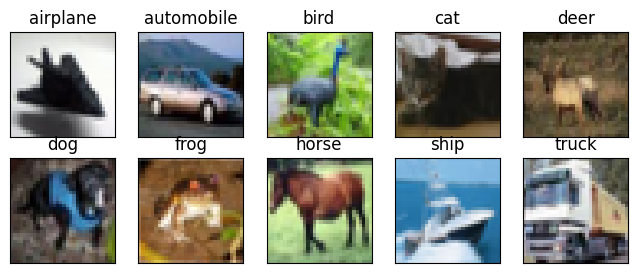

In [4]:
class_names = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

fig = plt.figure(figsize=(8,3))
num_classes = 10
for i in range(num_classes):
    ax = fig.add_subplot(2, 5, 1 + i, xticks=[], yticks=[])
    ax.set_title(class_names[i])
    img = next(img for img, label in cifar10 if label == i)
    plt.imshow(img)
plt.show()

**Transforms images to tensor**

In [5]:
from torchvision import transforms

to_tensor = transforms.ToTensor()
img_t = to_tensor(img)
img_t.shape

torch.Size([3, 32, 32])

**Transform Training and Normalization**

In [6]:
transformed_cifar10 = datasets.CIFAR10(
    data_path, train=True, download=False,
    transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4915, 0.4823, 0.4468),
                             (0.2470, 0.2435, 0.2616))
    ]))

**Transform validation**

In [7]:

transformed_cifar10_val = datasets.CIFAR10(
    data_path, train=False, download=False,
    transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4915, 0.4823, 0.4468),
                             (0.2470, 0.2435, 0.2616))
    ]))

**Neural Netwrok**

In [ ]:
import torch.nn as nn

n_out = 10

model = nn.Sequential(


    nn.Linear(3072, 256),
    nn.ReLU(),

    nn.Linear(256, 128),
    nn.ReLU(),

    nn.Linear(128, n_out)

).to(device)

loss_fn = nn.CrossEntropyLoss()

In [8]:
train_loader = torch.utils.data.DataLoader(
    transformed_cifar10,
    batch_size=256,
    shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    transformed_cifar10_val,
    batch_size=256,
    shuffle=False
)

**Training Loop**

In [ ]:
import torch.optim as optim
import time

learning_rate = 1e-2

optimizer = optim.SGD(
    model.parameters(),
    lr=learning_rate
)

n_epochs = 100

start_time = time.time()

model.train()

for epoch in range(n_epochs):

    for imgs, labels in train_loader:

        # Move data to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model(imgs.view(imgs.shape[0], -1))

        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print("Epoch: %d, Loss: %f" %
          (epoch + 1, loss.item()))

# Ensure GPU calculations have finished
if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

print("Training Time: %.2f seconds" %
      (end_time - start_time))

Epoch: 1, Loss: 2.000716
Epoch: 2, Loss: 1.896735
Epoch: 3, Loss: 1.636612
Epoch: 4, Loss: 1.577515
Epoch: 5, Loss: 1.709121
Epoch: 6, Loss: 1.751317
Epoch: 7, Loss: 1.506306
Epoch: 8, Loss: 1.533955
Epoch: 9, Loss: 1.581872
Epoch: 10, Loss: 1.509233
Epoch: 11, Loss: 1.489987
Epoch: 12, Loss: 1.472704
Epoch: 13, Loss: 1.354711
Epoch: 14, Loss: 1.392021
Epoch: 15, Loss: 1.523771
Epoch: 16, Loss: 1.181385
Epoch: 17, Loss: 1.403220
Epoch: 18, Loss: 1.186454
Epoch: 19, Loss: 1.316054
Epoch: 20, Loss: 1.301562
Epoch: 21, Loss: 1.375705
Epoch: 22, Loss: 1.454374
Epoch: 23, Loss: 1.360779
Epoch: 24, Loss: 1.307446
Epoch: 25, Loss: 1.250059
Epoch: 26, Loss: 1.436396
Epoch: 27, Loss: 1.369445
Epoch: 28, Loss: 1.251268
Epoch: 29, Loss: 1.118507
Epoch: 30, Loss: 1.430765
Epoch: 31, Loss: 1.160406
Epoch: 32, Loss: 1.123255
Epoch: 33, Loss: 0.988518
Epoch: 34, Loss: 1.174566
Epoch: 35, Loss: 1.241609
Epoch: 36, Loss: 0.961573
Epoch: 37, Loss: 0.933749
Epoch: 38, Loss: 0.901050
Epoch: 39, Loss: 1.02

**Accuracy Calculations**

In [ ]:
correct = 0
total = 0

with torch.no_grad():
    for imgs, labels in train_loader:

        # Move image and labels to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model(imgs.view(imgs.shape[0], -1))
        _, predicted = torch.max(outputs, dim=1)
        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Accuracy: %f" % (correct / total))

Accuracy: 0.780020


**Evaluation of accuracy**

In [ ]:
# Evaluation Accuracy

correct = 0
total = 0

model.eval()

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model(imgs.view(imgs.shape[0], -1))

        _, predicted = torch.max(outputs, dim=1)

        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Evaluation Accuracy: %f" % (correct / total))

Evaluation Accuracy: 0.473800


**Trainable Features**

In [ ]:
sum([p.numel() for p in model.parameters()
     if p.requires_grad == True])

820874

**Problem 1b**

In [ ]:
import torch.nn as nn

n_out = 10
#Increase Network Depth
model1b = nn.Sequential(


    nn.Linear(3072, 256),
    nn.ReLU(),

    nn.Linear(256, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),

    nn.Linear(128, n_out)

).to(device)

loss_fn = nn.CrossEntropyLoss()

**New Training Loop**

In [ ]:
import torch.optim as optim
import time

learning_rate = 1e-2

optimizer = optim.SGD(
    model1b.parameters(),
    lr=learning_rate
)

n_epochs = 100

start_time = time.time()

model1b.train()

for epoch in range(n_epochs):

    for imgs, labels in train_loader:

        # Move data to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model1b(imgs.view(imgs.shape[0], -1))

        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print("Epoch: %d, Loss: %f" %
          (epoch + 1, loss.item()))

# Ensure GPU calculations have finished
if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

print("Training Time: %.2f seconds" %
      (end_time - start_time))

Epoch: 1, Loss: 2.290354
Epoch: 2, Loss: 2.274375
Epoch: 3, Loss: 2.229296
Epoch: 4, Loss: 2.147695
Epoch: 5, Loss: 1.918201
Epoch: 6, Loss: 1.826859
Epoch: 7, Loss: 1.906154
Epoch: 8, Loss: 1.804333
Epoch: 9, Loss: 1.915038
Epoch: 10, Loss: 1.852167
Epoch: 11, Loss: 1.667684
Epoch: 12, Loss: 1.874736
Epoch: 13, Loss: 1.627694
Epoch: 14, Loss: 1.603471
Epoch: 15, Loss: 1.541718
Epoch: 16, Loss: 1.618009
Epoch: 17, Loss: 1.312864
Epoch: 18, Loss: 1.495465
Epoch: 19, Loss: 1.372699
Epoch: 20, Loss: 1.458494
Epoch: 21, Loss: 1.287460
Epoch: 22, Loss: 1.487964
Epoch: 23, Loss: 1.327253
Epoch: 24, Loss: 1.189688
Epoch: 25, Loss: 1.190108
Epoch: 26, Loss: 1.099374
Epoch: 27, Loss: 1.337942
Epoch: 28, Loss: 1.195018
Epoch: 29, Loss: 1.236247
Epoch: 30, Loss: 1.315405
Epoch: 31, Loss: 1.300322
Epoch: 32, Loss: 1.308552
Epoch: 33, Loss: 1.275508
Epoch: 34, Loss: 1.014518
Epoch: 35, Loss: 1.074788
Epoch: 36, Loss: 1.333446
Epoch: 37, Loss: 1.121766
Epoch: 38, Loss: 1.468323
Epoch: 39, Loss: 0.93

**Accuracy**

In [ ]:
correct = 0
total = 0

with torch.no_grad():
    for imgs, labels in train_loader:

        # Move image and labels to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model1b(imgs.view(imgs.shape[0], -1))
        _, predicted = torch.max(outputs, dim=1)
        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Accuracy: %f" % (correct / total))

Accuracy: 0.851380


**Evaluation of Accuracy**

In [ ]:
# Evaluation Accuracy

correct = 0
total = 0

model1b.eval()

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model1b(imgs.view(imgs.shape[0], -1))

        _, predicted = torch.max(outputs, dim=1)

        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Evaluation Accuracy: %f" % (correct / total))

Evaluation Accuracy: 0.506700


**updatetd Parameter count**

In [ ]:
sum(p.numel() for p in model1b.parameters()
    if p.requires_grad)

853898

**Problem 2a**

In [ ]:
n_out = 10
#Increase Network Depth
model2a = nn.Sequential(


    nn.Linear(3072, 256),
    nn.ReLU(),

    nn.Linear(256, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),



    nn.Linear(128, n_out)

).to(device)

loss_fn = nn.CrossEntropyLoss()

**Training loop**

In [ ]:
import torch.optim as optim
import time

learning_rate = 1e-2

optimizer = optim.SGD(
    model2a.parameters(),
    lr=learning_rate
)

n_epochs = 100

start_time = time.time()

model2a.train()

for epoch in range(n_epochs):

    for imgs, labels in train_loader:

        # Move data to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2a(imgs.view(imgs.shape[0], -1))

        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print("Epoch: %d, Loss: %f" %
          (epoch + 1, loss.item()))

# Ensure GPU calculations have finished
if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

print("Training Time: %.2f seconds" %
      (end_time - start_time))

Epoch: 1, Loss: 2.300849
Epoch: 2, Loss: 2.301173
Epoch: 3, Loss: 2.301613
Epoch: 4, Loss: 2.303376
Epoch: 5, Loss: 2.302582
Epoch: 6, Loss: 2.301168
Epoch: 7, Loss: 2.304355
Epoch: 8, Loss: 2.303752
Epoch: 9, Loss: 2.303199
Epoch: 10, Loss: 2.302736
Epoch: 11, Loss: 2.302807
Epoch: 12, Loss: 2.302480
Epoch: 13, Loss: 2.302830
Epoch: 14, Loss: 2.302556
Epoch: 15, Loss: 2.302536
Epoch: 16, Loss: 2.302560
Epoch: 17, Loss: 2.302722
Epoch: 18, Loss: 2.302632
Epoch: 19, Loss: 2.302567
Epoch: 20, Loss: 2.302614
Epoch: 21, Loss: 2.302630
Epoch: 22, Loss: 2.302637
Epoch: 23, Loss: 2.302604
Epoch: 24, Loss: 2.302566
Epoch: 25, Loss: 2.302510
Epoch: 26, Loss: 2.302468
Epoch: 27, Loss: 2.302670
Epoch: 28, Loss: 2.302654
Epoch: 29, Loss: 2.302704
Epoch: 30, Loss: 2.302669
Epoch: 31, Loss: 2.302602
Epoch: 32, Loss: 2.302586
Epoch: 33, Loss: 2.302652
Epoch: 34, Loss: 2.302591
Epoch: 35, Loss: 2.302706
Epoch: 36, Loss: 2.302612
Epoch: 37, Loss: 2.302559
Epoch: 38, Loss: 2.302573
Epoch: 39, Loss: 2.30

**Accuracy**

In [ ]:
correct = 0
total = 0

with torch.no_grad():
    for imgs, labels in train_loader:

        # Move image and labels to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2a(imgs.view(imgs.shape[0], -1))
        _, predicted = torch.max(outputs, dim=1)
        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Accuracy: %f" % (correct / total))

Accuracy: 0.103940


**Evalu accuraccy**

In [ ]:
# Evaluation Accuracy

correct = 0
total = 0

model2a.eval()

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2a(imgs.view(imgs.shape[0], -1))

        _, predicted = torch.max(outputs, dim=1)

        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Evaluation Accuracy: %f" % (correct / total))

Evaluation Accuracy: 0.104900


In [ ]:
sum(p.numel() for p in model2a.parameters()
    if p.requires_grad)

952970

**Problem 2b**

**Eperiment 1 Model**

In [ ]:
import torch.nn as nn

n_out = 10

model2b1 = nn.Sequential(


    nn.Linear(3072, 512),
    nn.ReLU(),

    nn.Linear(512, 256),
    nn.ReLU(),

    nn.Linear(256, n_out)

).to(device)

loss_fn = nn.CrossEntropyLoss()

**Experiment 2 Model**

In [ ]:
import torch.nn as nn

n_out = 10

model2b2 = nn.Sequential(


    nn.Linear(3072, 256),
    nn.Sigmoid(),

    nn.Linear(256, 128),
    nn.Sigmoid(),

    nn.Linear(128, n_out)

).to(device)

loss_fn = nn.CrossEntropyLoss()

**Experiment 3**

In [10]:
import torch.nn as nn

n_out = 10

model2b3 = nn.Sequential(


    nn.Linear(3072, 256),
    nn.Tanh(),

    nn.Linear(256, 128),
    nn.Tanh(),

    nn.Linear(128, n_out)

).to(device)

loss_fn = nn.CrossEntropyLoss()

**Experiment 1 Results**

In [ ]:
import torch.optim as optim
import time

learning_rate = 1e-2

optimizer = optim.SGD(
    model2b1.parameters(),
    lr=learning_rate
)

n_epochs = 100

start_time = time.time()

model2b1.train()

for epoch in range(n_epochs):

    for imgs, labels in train_loader:

        # Move data to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2b1(imgs.view(imgs.shape[0], -1))

        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print("Epoch: %d, Loss: %f" %
          (epoch + 1, loss.item()))

# Ensure GPU calculations have finished
if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

print("Training Time: %.2f seconds" %
      (end_time - start_time))

Epoch: 1, Loss: 1.920063
Epoch: 2, Loss: 1.821523
Epoch: 3, Loss: 1.867023
Epoch: 4, Loss: 1.556413
Epoch: 5, Loss: 1.538264
Epoch: 6, Loss: 1.711282
Epoch: 7, Loss: 1.737999
Epoch: 8, Loss: 1.413451
Epoch: 9, Loss: 1.354674
Epoch: 10, Loss: 1.386276
Epoch: 11, Loss: 1.411980
Epoch: 12, Loss: 1.389893
Epoch: 13, Loss: 1.334269
Epoch: 14, Loss: 1.226448
Epoch: 15, Loss: 1.164248
Epoch: 16, Loss: 1.413349
Epoch: 17, Loss: 1.474648
Epoch: 18, Loss: 1.342186
Epoch: 19, Loss: 1.337337
Epoch: 20, Loss: 1.278976
Epoch: 21, Loss: 1.368640
Epoch: 22, Loss: 1.186094
Epoch: 23, Loss: 1.191576
Epoch: 24, Loss: 0.964784
Epoch: 25, Loss: 1.289840
Epoch: 26, Loss: 1.158124
Epoch: 27, Loss: 1.223472
Epoch: 28, Loss: 1.131414
Epoch: 29, Loss: 1.198809
Epoch: 30, Loss: 1.070889
Epoch: 31, Loss: 1.118838
Epoch: 32, Loss: 0.976318
Epoch: 33, Loss: 0.979155
Epoch: 34, Loss: 1.132888
Epoch: 35, Loss: 1.049989
Epoch: 36, Loss: 0.886725
Epoch: 37, Loss: 1.072338
Epoch: 38, Loss: 1.062194
Epoch: 39, Loss: 0.92

**Accuracy**

In [ ]:
correct = 0
total = 0

with torch.no_grad():
    for imgs, labels in train_loader:

        # Move image and labels to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2b1(imgs.view(imgs.shape[0], -1))
        _, predicted = torch.max(outputs, dim=1)
        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Accuracy: %f" % (correct / total))

Accuracy: 0.931980


eval accuracy

In [ ]:
# Evaluation Accuracy

correct = 0
total = 0

model2b1.eval()

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2b1(imgs.view(imgs.shape[0], -1))

        _, predicted = torch.max(outputs, dim=1)

        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Evaluation Accuracy: %f" % (correct / total))

Evaluation Accuracy: 0.530300


In [ ]:
sum(p.numel() for p in model2b1.parameters()
    if p.requires_grad)

1707274

**Experiment 2 Results**

In [ ]:
import torch.optim as optim
import time

learning_rate = 1e-2

optimizer = optim.SGD(
    model2b2.parameters(),
    lr=learning_rate
)

n_epochs = 100

start_time = time.time()

model2b2.train()

for epoch in range(n_epochs):

    for imgs, labels in train_loader:

        # Move data to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2b2(imgs.view(imgs.shape[0], -1))

        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print("Epoch: %d, Loss: %f" %
          (epoch + 1, loss.item()))

# Ensure GPU calculations have finished
if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

print("Training Time: %.2f seconds" %
      (end_time - start_time))

Epoch: 1, Loss: 2.287981
Epoch: 2, Loss: 2.271082
Epoch: 3, Loss: 2.228877
Epoch: 4, Loss: 2.223070
Epoch: 5, Loss: 2.171074
Epoch: 6, Loss: 2.159766
Epoch: 7, Loss: 2.137005
Epoch: 8, Loss: 2.095559
Epoch: 9, Loss: 2.048719
Epoch: 10, Loss: 2.176952
Epoch: 11, Loss: 2.108415
Epoch: 12, Loss: 2.062665
Epoch: 13, Loss: 2.020063
Epoch: 14, Loss: 1.940642
Epoch: 15, Loss: 2.000409
Epoch: 16, Loss: 1.980912
Epoch: 17, Loss: 2.029350
Epoch: 18, Loss: 1.940446
Epoch: 19, Loss: 1.880663
Epoch: 20, Loss: 1.991334
Epoch: 21, Loss: 1.928974
Epoch: 22, Loss: 1.940145
Epoch: 23, Loss: 1.994896
Epoch: 24, Loss: 1.867372
Epoch: 25, Loss: 1.954996
Epoch: 26, Loss: 1.899935
Epoch: 27, Loss: 1.808532
Epoch: 28, Loss: 1.995192
Epoch: 29, Loss: 1.910508
Epoch: 30, Loss: 1.760191
Epoch: 31, Loss: 1.794290
Epoch: 32, Loss: 1.869543
Epoch: 33, Loss: 1.730621
Epoch: 34, Loss: 1.929464
Epoch: 35, Loss: 1.928793
Epoch: 36, Loss: 1.879168
Epoch: 37, Loss: 1.795846
Epoch: 38, Loss: 1.776603
Epoch: 39, Loss: 1.82

**Accuracy**

In [ ]:
correct = 0
total = 0

with torch.no_grad():
    for imgs, labels in train_loader:

        # Move image and labels to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2b2(imgs.view(imgs.shape[0], -1))
        _, predicted = torch.max(outputs, dim=1)
        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Accuracy: %f" % (correct / total))

Accuracy: 0.420620


**Evaluation Accuracy**

In [ ]:
# Evaluation Accuracy

correct = 0
total = 0

model2b2.eval()

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2b2(imgs.view(imgs.shape[0], -1))

        _, predicted = torch.max(outputs, dim=1)

        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Evaluation Accuracy: %f" % (correct / total))

Evaluation Accuracy: 0.414800


In [ ]:
sum(p.numel() for p in model2b2.parameters()
    if p.requires_grad)

820874

**Experiment 3 Results**

In [11]:
import torch.optim as optim
import time

learning_rate = 1e-2

optimizer = optim.SGD(
    model2b3.parameters(),
    lr=learning_rate
)

n_epochs = 100

start_time = time.time()

model2b3.train()

for epoch in range(n_epochs):

    for imgs, labels in train_loader:

        # Move data to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2b3(imgs.view(imgs.shape[0], -1))

        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print("Epoch: %d, Loss: %f" %
          (epoch + 1, loss.item()))

# Ensure GPU calculations have finished
if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

print("Training Time: %.2f seconds" %
      (end_time - start_time))

Epoch: 1, Loss: 1.970577
Epoch: 2, Loss: 1.892009
Epoch: 3, Loss: 1.871505
Epoch: 4, Loss: 1.773788
Epoch: 5, Loss: 1.702983
Epoch: 6, Loss: 1.582409
Epoch: 7, Loss: 1.626857
Epoch: 8, Loss: 1.574711
Epoch: 9, Loss: 1.745796
Epoch: 10, Loss: 1.669784
Epoch: 11, Loss: 1.757618
Epoch: 12, Loss: 1.723252
Epoch: 13, Loss: 1.644144
Epoch: 14, Loss: 1.632367
Epoch: 15, Loss: 1.655833
Epoch: 16, Loss: 1.558470
Epoch: 17, Loss: 1.608615
Epoch: 18, Loss: 1.429482
Epoch: 19, Loss: 1.627430
Epoch: 20, Loss: 1.503185
Epoch: 21, Loss: 1.555938
Epoch: 22, Loss: 1.428977
Epoch: 23, Loss: 1.492155
Epoch: 24, Loss: 1.401096
Epoch: 25, Loss: 1.525134
Epoch: 26, Loss: 1.664866
Epoch: 27, Loss: 1.427496
Epoch: 28, Loss: 1.359641
Epoch: 29, Loss: 1.211322
Epoch: 30, Loss: 1.142483
Epoch: 31, Loss: 1.463550
Epoch: 32, Loss: 1.242207
Epoch: 33, Loss: 1.264027
Epoch: 34, Loss: 1.470777
Epoch: 35, Loss: 1.591080
Epoch: 36, Loss: 1.364508
Epoch: 37, Loss: 1.525527
Epoch: 38, Loss: 1.288774
Epoch: 39, Loss: 1.48

**Accuracy**

In [12]:
correct = 0
total = 0

with torch.no_grad():
    for imgs, labels in train_loader:

        # Move image and labels to GPU
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2b3(imgs.view(imgs.shape[0], -1))
        _, predicted = torch.max(outputs, dim=1)
        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Accuracy: %f" % (correct / total))

Accuracy: 0.810820


**Acurracy Evaluation**

In [13]:
# Evaluation Accuracy

correct = 0
total = 0

model2b3.eval()

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model2b3(imgs.view(imgs.shape[0], -1))

        _, predicted = torch.max(outputs, dim=1)

        total += labels.shape[0]
        correct += int((predicted == labels).sum())

print("Evaluation Accuracy: %f" % (correct / total))

Evaluation Accuracy: 0.466900


In [14]:
sum(p.numel() for p in model2b3.parameters()
    if p.requires_grad)

820874